# Notebook 01 (v2): EDA and Preprocessing
**AID 427: New Trends in Data Science, Project Phase 1**
**MultiCaRe-Fusion: Multimodal Clinical Image Classification from Case Reports**



## 1. Problem introduction
Clinicians and medical-AI systems handle huge collections of images (CT, MRI, X-ray, pathology slides, endoscopy, ECG...) whose labels are often missing or inconsistent. We build a **multimodal classifier** that predicts the type of a medical image from:
- the **image** itself,
- its **caption** (free text), and
- the **clinical context** (patient age, gender, case text).

**Targets:** `image_type` (7 classes) and `image_subtype` (up to 40 classes, we keep those with enough images).
**Goal of Phase 1:** reduce dimensionality, select features, train models and evaluate them properly, while handling the noise in this dataset.

## 2. Dataset description
**MultiCaRe v2.1** (Nievas Offidani, Zenodo DOI 10.5281/zenodo.14994046): open-access, de-identified clinical **case reports** from PubMed Central.

| Item | Value (from our own profiling) |
|---|---|
| Images | 130,791 (`.webp`) |
| Patients / clinical cases | 33,129 with images / 93,816 in total |
| Case reports (articles) | 72,581 |
| Modalities | images + captions + case text + age + gender + hierarchical labels |
| Labels | `image_type` (7), `image_subtype` (40), `radiology_region` (9), `radiology_region_granular` (19), `radiology_view` (9), multilabel lists |

**Why it is a difficult, noisy dataset** (checked below): labels are derived automatically from captions, extreme class imbalance (up to 1025x between subtypes), noisy and duplicated captions, 62% of images are sub-images cut from larger figures, missing age/gender, widely varying image size and quality, and several images per patient (leakage risk).

In [1]:
import os, ast, re, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import StratifiedGroupKFold
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

# ---------------- configuration ----------------
# Finds the DataSet folder automatically (notebook in ../Notebooks, or inside DataSet itself)
CANDIDATES = ["../DataSet", "DataSet", "."]
DATA_DIR = next((p for p in CANDIDATES if os.path.exists(os.path.join(p, "captions_and_labels.csv")) or os.path.exists(os.path.join(p, "sample.csv"))), None)
assert DATA_DIR is not None, "DataSet folder not found: set DATA_DIR by hand, e.g. DATA_DIR = r'C:\path\to\DataSet'"
OUT_DIR  = os.path.join(DATA_DIR, "outputs")
FIG_DIR  = os.path.join(OUT_DIR, "figures")
SEED     = 42
MIN_PER_CLASS = 250            # keep image_subtype classes with at least this many images
MAX_PER_CLASS = 1000           # v2: 1000 (was 600) -> about 21k images; more data per class helps generalisation
os.makedirs(FIG_DIR, exist_ok=True)
np.random.seed(SEED)

def savefig(name):
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, name), dpi=150, bbox_inches="tight"); plt.show()

## 3. Load the data

In [2]:
FULL = os.path.exists(os.path.join(DATA_DIR, "captions_and_labels.csv"))
if FULL:
    cl = pd.read_csv(os.path.join(DATA_DIR, "captions_and_labels.csv"))
    cs = pd.read_parquet(os.path.join(DATA_DIR, "cases.parquet"))      # one row per article, nested list of cases
    cs = pd.json_normalize(cs.explode("cases").dropna(subset=["cases"])["cases"].tolist())
    cs = cs[["case_id", "age", "gender", "case_text"]].drop_duplicates("case_id")
    df = cl.merge(cs, left_on="patient_id", right_on="case_id", how="left")
else:                                                                  # small test sample (Claude's copy)
    print("Full files not found -> using sample.csv (test mode)")
    df = pd.read_csv(os.path.join(DATA_DIR, "sample.csv"))
    MIN_PER_CLASS, MAX_PER_CLASS = 40, 100
df["article_id"] = df["patient_id"].str.split("_").str[0]
print("FULL mode:", FULL, "| rows:", len(df), "| patients:", df.patient_id.nunique(), "| articles:", df.article_id.nunique())
df.head(3).T

FULL mode: True | rows: 130791 | patients: 33129 | articles: 30526


,0,1,2
file_id,file_0000000,file_0000001,file_0000002
file,PMC10000323_jbsr-107-1-3012-g3_undivided_1_1.webp,PMC10000728_fmed-09-985235-g001_A_1_3.webp,PMC10000728_fmed-09-985235-g001_B_2_3.webp
main_image,PMC10000323_01_jbsr-107-1-3012-g3.jpg,PMC10000728_01_fmed-09-985235-g001.jpg,PMC10000728_01_fmed-09-985235-g001.jpg
image_component,undivided,a,b
patient_id,PMC10000323_01,PMC10000728_01,PMC10000728_01
license,CC BY,CC BY,CC BY
file_size,105470,25364,27484
caption,Pathological result.,Intraoperative exploration revealed a teratoma...,The teratoma was disconnected from the posteri...
case_substring,['Figure 3'],['Figure 1A'],['Figure 1B']
image_type,pathology,medical_photograph,medical_photograph


## 4. Exploratory data analysis (raw data)

### 4.1 Class imbalance

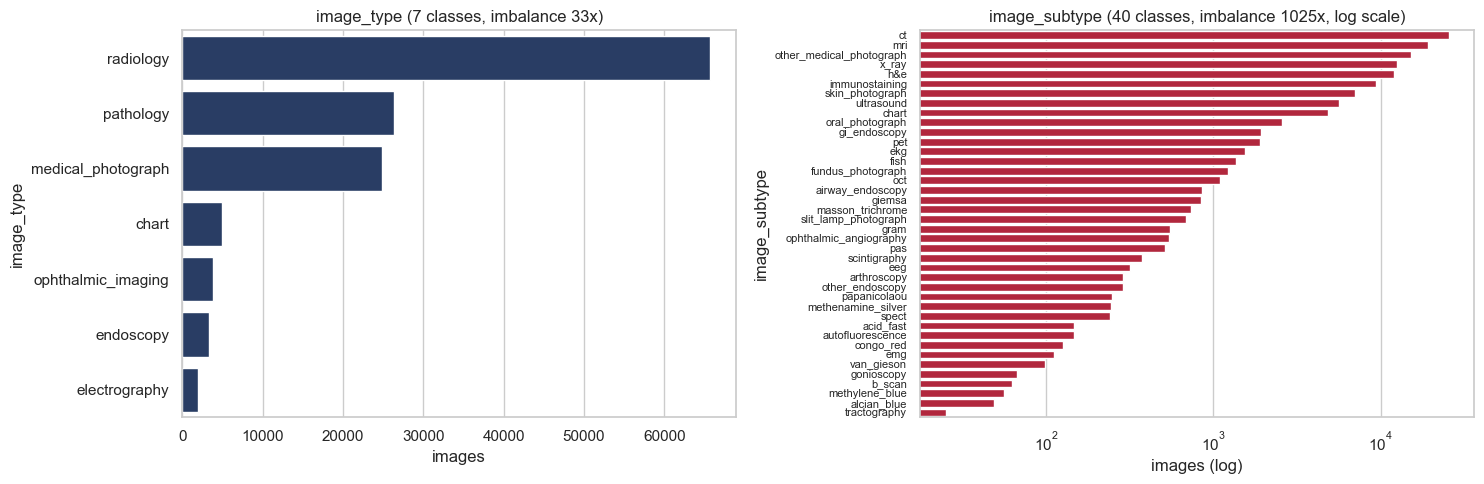

Subtypes with < 100 images: 6 | < 500 images: 17


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
vc = df.image_type.value_counts()
sns.barplot(x=vc.values, y=vc.index, ax=ax[0], color="#1F3A6E"); ax[0].set_title(f"image_type ({len(vc)} classes, imbalance {vc.max()/vc.min():.0f}x)"); ax[0].set_xlabel("images")
vs = df.image_subtype.value_counts()
sns.barplot(x=vs.values, y=vs.index, ax=ax[1], color="#C8102E"); ax[1].set_xscale("log")
ax[1].set_title(f"image_subtype ({len(vs)} classes, imbalance {vs.max()/vs.min():.0f}x, log scale)"); ax[1].set_xlabel("images (log)")
ax[1].tick_params(axis="y", labelsize=8)
savefig("01_class_imbalance.png")
print("Subtypes with < 100 images:", (vs < 100).sum(), "| < 500 images:", (vs < 500).sum())

### 4.2 Missing values

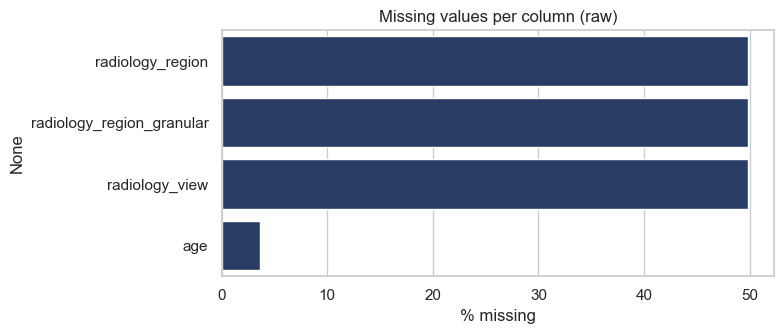

radiology_region missing among NON-radiology images: 100.0 % (empty by design)
radiology_region missing among radiology images:    0.0 %
age missing: 3.6 %  | gender 'Unknown': 2.9 %


In [4]:
miss = df.isna().mean().sort_values(ascending=False)
miss = miss[miss > 0]
plt.figure(figsize=(8, 3.5)); sns.barplot(x=miss.values * 100, y=miss.index, color="#1F3A6E")
plt.xlabel("% missing"); plt.title("Missing values per column (raw)"); savefig("02_missing_values.png")
rad = df.image_type == "radiology"
print("radiology_region missing among NON-radiology images:", round(df.loc[~rad, "radiology_region"].isna().mean() * 100, 1), "% (empty by design)")
print("radiology_region missing among radiology images:   ", round(df.loc[rad, "radiology_region"].isna().mean() * 100, 1), "%")
print("age missing:", round(df.age.isna().mean() * 100, 1), "%  | gender 'Unknown':", round((df.gender == "Unknown").mean() * 100, 1), "%")

### 4.3 Label noise (multilabel list vs. image_subtype)

In [5]:
def parse_list(x):
    try: return ast.literal_eval(x) if isinstance(x, str) else []
    except Exception: return []
df["labels_sup"]  = df["ml_labels_for_supervised_classification"].map(parse_list)
df["labels_semi"] = df["gt_labels_for_semisupervised_classification"].map(parse_list)
df["n_labels_sup"]  = df.labels_sup.str.len()
df["n_labels_semi"] = df.labels_semi.str.len()
ok = [(s in l) for s, l in zip(df.image_subtype, df.labels_sup)]
print("image_subtype present in supervised multilabel list:", round(np.mean(ok) * 100, 2), "%")
print("rows with a non-empty semi-supervised label list:", round((df.n_labels_semi > 0).mean() * 100, 1), "%")
print(df.n_labels_sup.value_counts().sort_index().to_string())

image_subtype present in supervised multilabel list: 100.0 %
rows with a non-empty semi-supervised label list: 56.5 %
n_labels_sup
1     4877
2    60274
3      237
4    56015
5     9388


### 4.4 Captions (text noise)

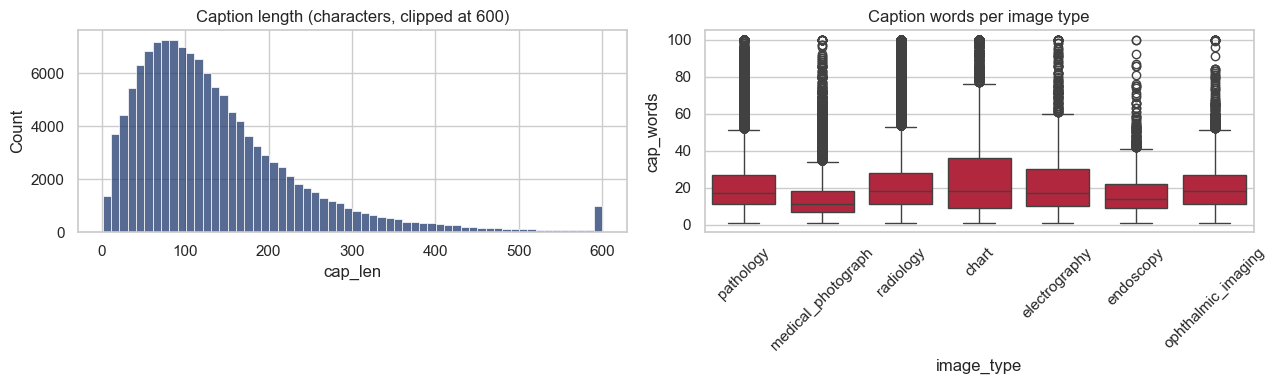

very short captions (<= 15 chars): 3252 | duplicate captions: 11338 | captions with panel markers like (A): 31727


caption
Medical image.    578
Axial.            150
Coronal.          108
Sagittal.          96
Lateral.           32
Preoperative.      25
Sagittal view.     21
Timeline.          20
Name: count, dtype: int64

In [6]:
df["cap_len"] = df.caption.fillna("").str.len()
df["cap_words"] = df.caption.fillna("").str.split().str.len()
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df.cap_len.clip(upper=600), bins=60, ax=ax[0], color="#1F3A6E"); ax[0].set_title("Caption length (characters, clipped at 600)")
sns.boxplot(data=df, x="image_type", y=df.cap_words.clip(upper=100), ax=ax[1], color="#C8102E"); ax[1].set_title("Caption words per image type"); ax[1].tick_params(axis="x", rotation=45)
savefig("03_caption_length.png")
print("very short captions (<= 15 chars):", (df.cap_len <= 15).sum(), "| duplicate captions:", df.caption.duplicated().sum(),
      "| captions with panel markers like (A):", df.caption.str.contains(r"\(\s*[A-Za-z]\s*[,)]", regex=True, na=False).sum())
df.loc[df.cap_len <= 15, "caption"].value_counts().head(8)

### 4.5 Clinical context (age, gender, case text)

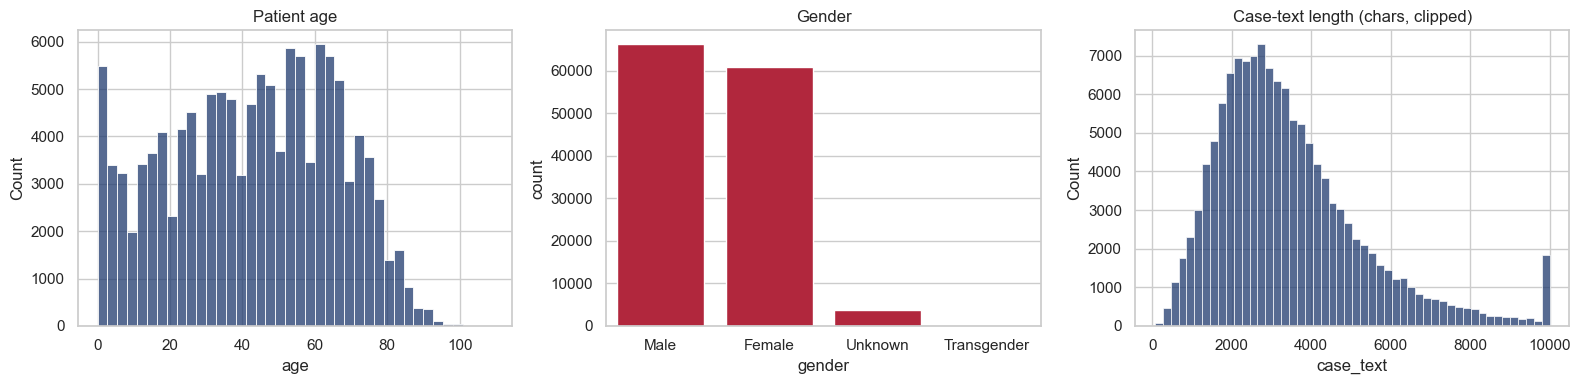

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df.age.dropna(), bins=40, ax=ax[0], color="#1F3A6E"); ax[0].set_title("Patient age")
sns.countplot(data=df, x="gender", ax=ax[1], color="#C8102E", order=df.gender.value_counts().index); ax[1].set_title("Gender")
sns.histplot(df.case_text.fillna("").str.len().clip(upper=10000), bins=50, ax=ax[2], color="#1F3A6E"); ax[2].set_title("Case-text length (chars, clipped)")
savefig("04_clinical_context.png")

### 4.6 Patients, figures and sub-images (leakage risk)

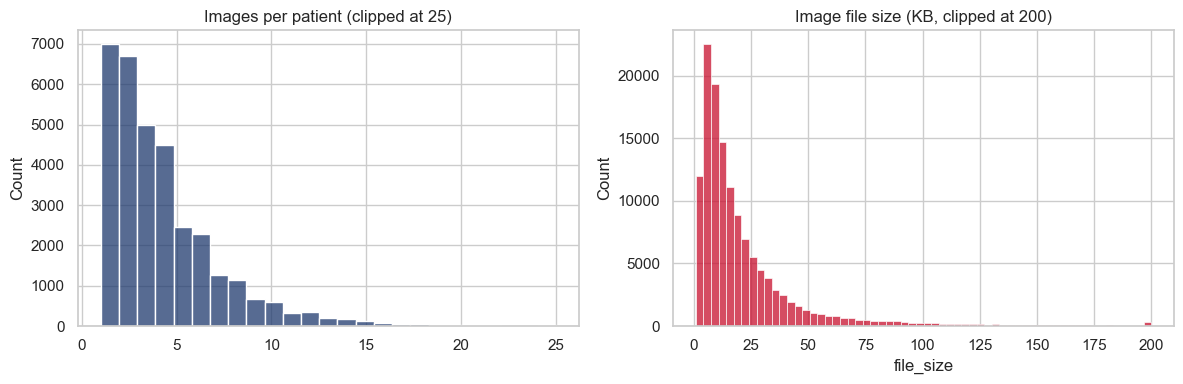

Patients: 33129 | main figures: 75319 | sub-images: 62.5% of all images
Images per patient: mean 3.95 | max 47


In [8]:
per_pat = df.groupby("patient_id").size()
split_share = (df.image_component != "undivided").mean() * 100
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(per_pat.clip(upper=25), bins=25, ax=ax[0], color="#1F3A6E"); ax[0].set_title("Images per patient (clipped at 25)")
sns.histplot(df.file_size.clip(upper=200000) / 1000, bins=60, ax=ax[1], color="#C8102E"); ax[1].set_title("Image file size (KB, clipped at 200)")
savefig("05_patients_and_files.png")
print(f"Patients: {df.patient_id.nunique()} | main figures: {df.main_image.nunique()} | sub-images: {split_share:.1f}% of all images")
print("Images per patient: mean", round(per_pat.mean(), 2), "| max", per_pat.max())

## 5. Cleaning and preprocessing
Steps: clean captions, handle missing age/gender (impute and flag), build file paths and verify the image files exist, record image properties, build a capped subset, and split by **article** so that images from the same article/patient never appear in both train and test.

In [9]:
def clean_caption(s):
    s = str(s).lower()
    s = re.sub(r"\(\s*[a-z]\s*(,\s*[a-z]\s*)*\)", " ", s)      # panel markers: (a), (b, c)
    s = re.sub(r"[^a-z0-9\s\-\./%]", " ", s)                       # strange symbols
    return re.sub(r"\s+", " ", s).strip()

d = df.copy()
d["caption_clean"] = d.caption.map(clean_caption)
d["caption_missing"] = (d.caption_clean.str.len() < 3).astype(int)

# age: missing flag + median imputation, plus age groups
d["age_missing"] = d.age.isna().astype(int)
d["age_imputed"] = d.age.fillna(d.age.median())
d["age_group"] = pd.cut(d.age_imputed, [-1, 1, 12, 18, 40, 65, 200], labels=["infant", "child", "teen", "adult", "middle", "senior"])
d["gender_clean"] = d.gender.where(d.gender.isin(["Male", "Female"]), "Other_Unknown").fillna("Other_Unknown")
d["case_text_short"] = d.case_text.fillna("").str.slice(0, 1500)

# image path (rule from the data dictionary)
d["path"] = [os.path.join(DATA_DIR, f[:4], f[:5], f) for f in d.file]
print("rows:", len(d), "| caption_missing:", d.caption_missing.sum(), "| age_missing:", d.age_missing.sum())
d[["caption", "caption_clean"]].sample(4, random_state=SEED).to_string()

rows: 130791 | caption_missing: 24 | age_missing: 4765


'                                                                                                                                                                                                                                                                                       caption                                                                                                                                                                                                                                                                   caption_clean\n86546   Coronal view T1 DIXON FS post gadolinium, slice thickness 3 mm. Arrow: Cavernous sinus, Triangle: Pars cavernosa of the internal carotid artery. Initial MRI: Thrombosis of the cavernous sinus and involvement of the internal carotid artery with hyperemia of the vasa vasorum (A).  coronal view t1 dixon fs post gadolinium slice thickness 3 mm. arrow cavernous sinus triangle pars cavernosa of the internal carotid artery. initial mr

### 5.1 Build the working subset

In [10]:
vc = d.image_subtype.value_counts()
keep = vc[vc >= MIN_PER_CLASS].index
dropped = vc[vc < MIN_PER_CLASS]
print(f"Keeping {len(keep)} of {len(vc)} subtypes; dropping {len(dropped)} rare ones ({dropped.sum()} images): {list(dropped.index)}")
parts = [g.sample(min(len(g), MAX_PER_CLASS), random_state=SEED) for _, g in d[d.image_subtype.isin(keep)].groupby("image_subtype")]
sub = pd.concat(parts).reset_index(drop=True)
print("subset size:", len(sub), "| patients:", sub.patient_id.nunique(), "| articles:", sub.article_id.nunique())

Keeping 27 of 40 subtypes; dropping 13 rare ones (1618 images): ['papanicolaou', 'methenamine_silver', 'spect', 'acid_fast', 'autofluorescence', 'congo_red', 'emg', 'van_gieson', 'gonioscopy', 'b_scan', 'methylene_blue', 'alcian_blue', 'tractography']
subset size: 21989 | patients: 13659 | articles: 13210


### 5.2 Verify images and record their properties

unreadable images removed: 1


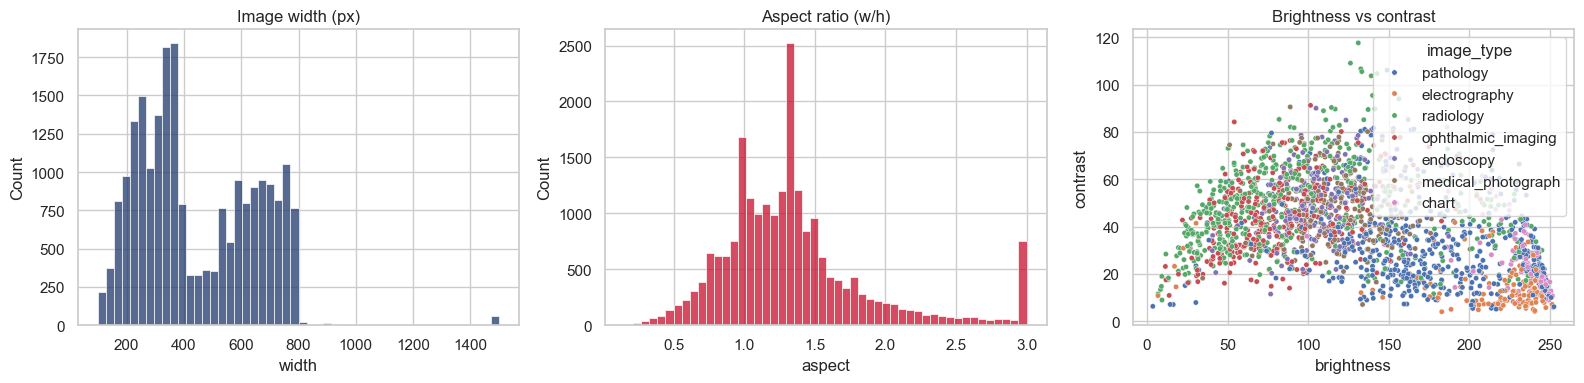

{'RGB': 21988}


In [11]:
from PIL import Image
CHECK_IMAGES = os.path.isdir(os.path.join(DATA_DIR, "PMC1"))
if CHECK_IMAGES:
    W, H, MODE, BRI, CON, OK = [], [], [], [], [], []
    for p in sub.path:
        try:
            with Image.open(p) as im:
                W.append(im.width); H.append(im.height); MODE.append(im.mode)
                g = np.asarray(im.convert("L").resize((32, 32)), dtype=np.float32)
                BRI.append(g.mean()); CON.append(g.std()); OK.append(True)
        except Exception:
            W.append(np.nan); H.append(np.nan); MODE.append(None); BRI.append(np.nan); CON.append(np.nan); OK.append(False)
    sub["width"], sub["height"], sub["mode"], sub["brightness"], sub["contrast"], sub["img_ok"] = W, H, MODE, BRI, CON, OK
    print("unreadable images removed:", (~sub.img_ok).sum())
    sub = sub[sub.img_ok].reset_index(drop=True)
    sub["aspect"] = sub.width / sub.height
    fig, ax = plt.subplots(1, 3, figsize=(16, 4))
    sns.histplot(sub.width.clip(upper=1500), bins=50, ax=ax[0], color="#1F3A6E"); ax[0].set_title("Image width (px)")
    sns.histplot(sub.aspect.clip(upper=3), bins=50, ax=ax[1], color="#C8102E"); ax[1].set_title("Aspect ratio (w/h)")
    sns.scatterplot(data=sub.sample(min(2000, len(sub)), random_state=SEED), x="brightness", y="contrast", hue="image_type", s=15, ax=ax[2]); ax[2].set_title("Brightness vs contrast")
    savefig("06_image_properties.png")
    print(sub["mode"].value_counts().to_dict())
else:
    print("PMC1 folder not found -> skipping image checks (check DATA_DIR points to the folder with PMC1..PMC9)")

### 5.3 Example images

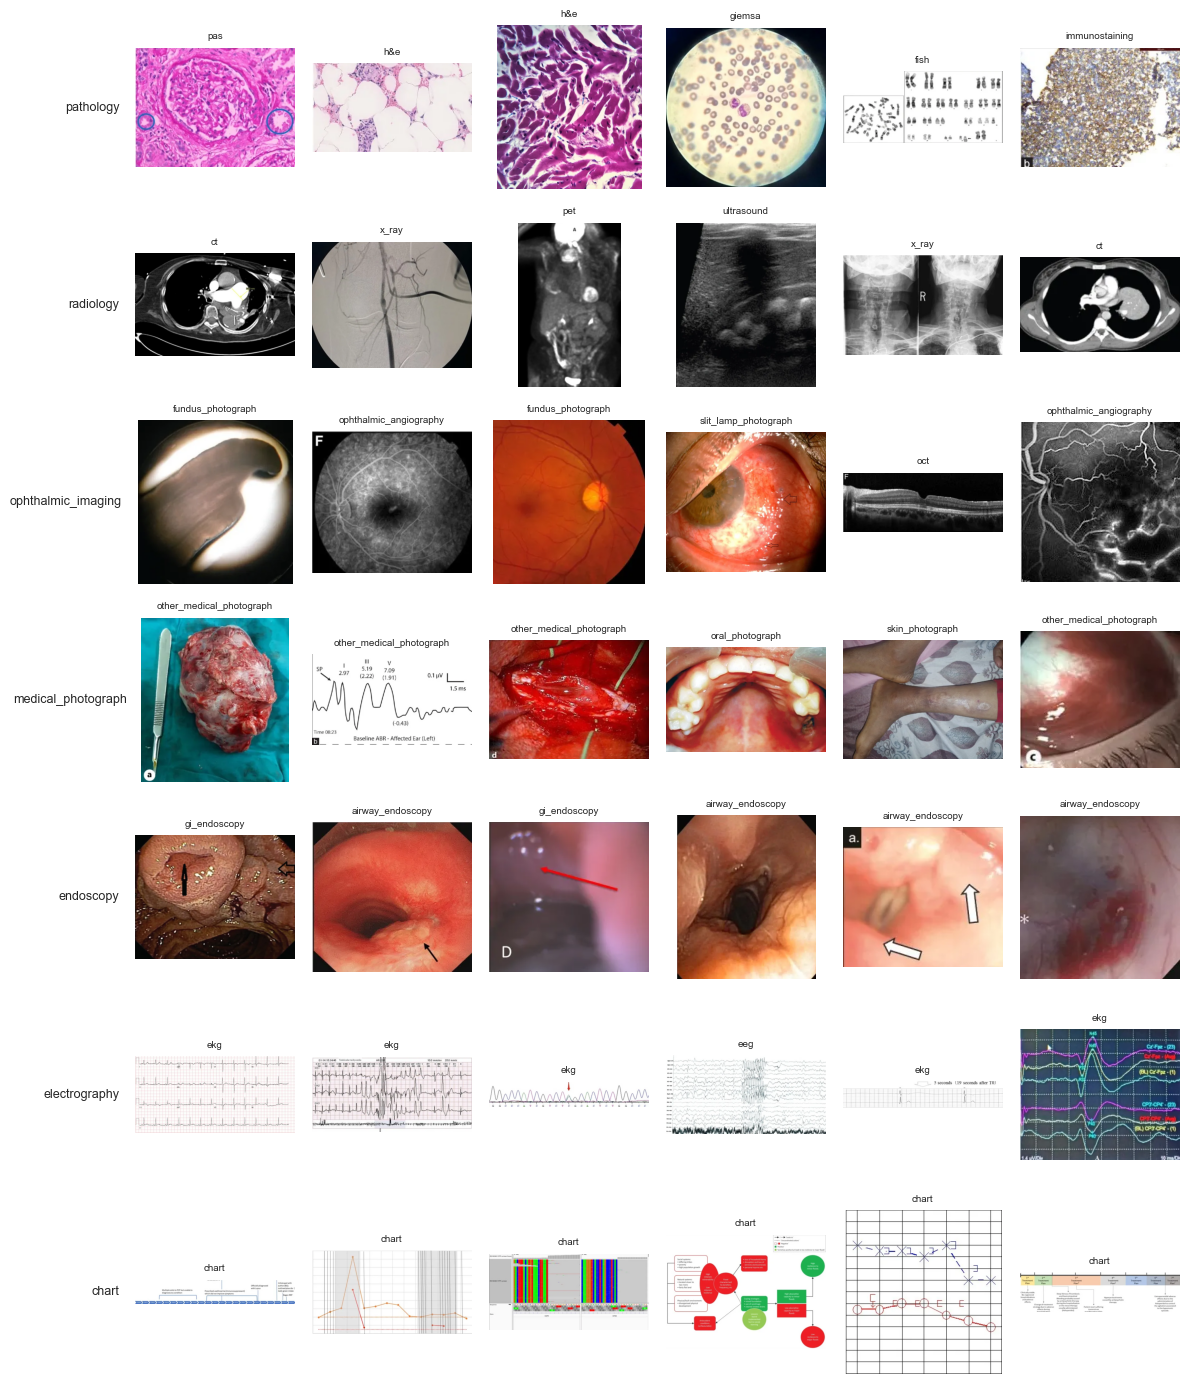

In [12]:
if CHECK_IMAGES:
    types = list(sub.image_type.value_counts().index); n = 6
    fig, axes = plt.subplots(len(types), n, figsize=(2 * n, 2 * len(types)))
    for i, t in enumerate(types):
        rows = sub[sub.image_type == t].sample(n, random_state=SEED)
        for j, (_, r) in enumerate(rows.iterrows()):
            axes[i, j].imshow(Image.open(r.path).convert("RGB")); axes[i, j].axis("off")
            axes[i, j].set_title(r.image_subtype, fontsize=7)
        axes[i, 0].text(-0.1, 0.5, t, transform=axes[i, 0].transAxes, ha="right", va="center", fontsize=9, rotation=0)
    savefig("07_example_images.png")

### 5.4 Patient-safe split (80% train / 20% test) and 5 folds
Group by **article** (`article_id`) so images of the same patient, figure or article stay together. `StratifiedGroupKFold` keeps class proportions similar. Fold 0 is the 20% **test** set; folds 1-4 are used for cross-validation on the training part.

train: 17673 (80%) | test: 4315 (20%) | articles shared: 0


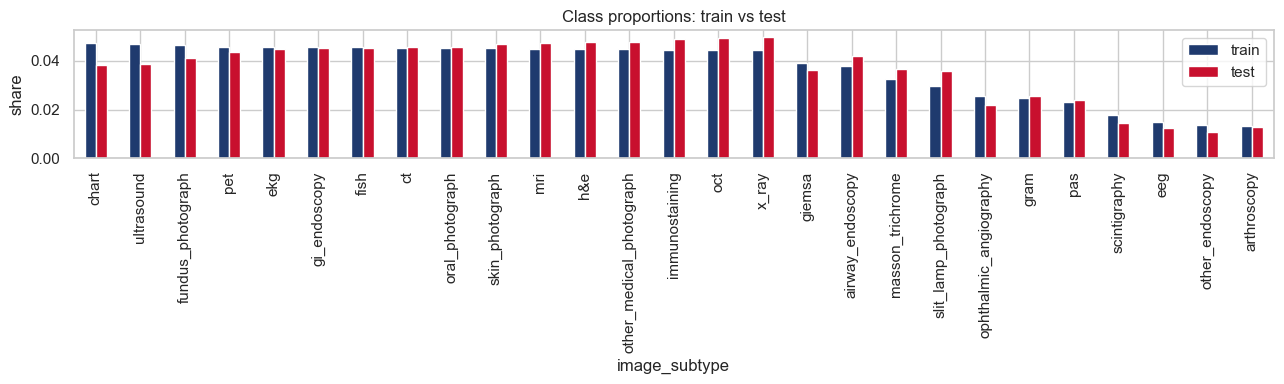

In [13]:
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
sub["fold"] = -1
for k, (_, te) in enumerate(sgkf.split(sub, sub.image_subtype, groups=sub.article_id)):
    sub.loc[sub.index[te], "fold"] = k
sub["split"] = np.where(sub.fold == 0, "test", "train")
tr, te = sub[sub.split == "train"], sub[sub.split == "test"]
assert set(tr.article_id).isdisjoint(set(te.article_id)), "LEAKAGE: articles shared between train and test"
print(f"train: {len(tr)} ({len(tr)/len(sub):.0%}) | test: {len(te)} ({len(te)/len(sub):.0%}) | articles shared: 0")
prop = pd.concat([tr.image_subtype.value_counts(normalize=True).rename("train"), te.image_subtype.value_counts(normalize=True).rename("test")], axis=1)
prop.plot.bar(figsize=(13, 4), color=["#1F3A6E", "#C8102E"]); plt.title("Class proportions: train vs test"); plt.ylabel("share"); savefig("08_split_proportions.png")

### 5.5 Before vs after (summary for the report)

In [14]:
before = d.image_subtype.value_counts().rename("before (all data)")
after = sub.image_subtype.value_counts().rename("after (subset)")
tab = pd.concat([before, after], axis=1).fillna(0).astype(int)
print(f"Imbalance ratio before: {before.max()/before.min():.0f}x | after: {after.max()/after.min():.1f}x")
print(f"Images: {len(d)} -> {len(sub)} | classes: {before.shape[0]} -> {after.shape[0]}")
tab

Imbalance ratio before: 1025x | after: 3.5x
Images: 130791 -> 21988 | classes: 40 -> 27


,before (all data),after (subset)
image_subtype,,
ct,25614,1000
mri,19235,1000
other_medical_photograph,15221,1000
x_ray,12586,1000
h&e,12009,1000
immunostaining,9327,1000
skin_photograph,7023,1000
ultrasound,5670,1000
chart,4877,1000


## 6. Save outputs for the next notebook

In [15]:
cols = ["file_id", "file", "path", "main_image", "patient_id", "article_id", "image_type", "image_subtype", "radiology_region", "radiology_view",
        "labels_sup", "caption", "caption_clean", "caption_missing", "age", "age_imputed", "age_missing", "age_group", "gender_clean",
        "case_text_short", "fold", "split"]
cols += [c for c in ["width", "height", "aspect", "brightness", "contrast"] if c in sub.columns]
out = sub[cols].copy()
out.to_parquet(os.path.join(OUT_DIR, "subset.parquet"), index=False)
out.drop(columns=["case_text_short"]).to_csv(os.path.join(OUT_DIR, "subset_light.csv"), index=False)
print("saved:", os.path.join(OUT_DIR, "subset.parquet"), out.shape)

saved: ../DataSet\outputs\subset.parquet (21988, 27)
